# 02 · What a MIRT fit learns

Multidimensional IRT models the chance that model $m$ answers question $i$ correctly as

$$P(Y_{mi}=1)=\sigma(\theta_m^\top\alpha_i-\beta_i)$$

- $\theta_m$: the model's **ability**, a vector of D numbers
- $\alpha_i$: the question's **discrimination**, i.e. which ability directions it tests and how sharply
- $\beta_i$: the question's **difficulty**

Here D = 2, fitted on the training models of family split 0 (the same split the experiment uses).

In [1]:
import sys

sys.path.insert(0, "../scripts/irt")  # for the efficbench loader

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from efficbench import load

from cabench.irt import fit_mirt, fit_theta, predict_proba
from cabench.splits import behaviour_families, split_models

Y, models, items = load()
Y = Y.astype(np.float32)

# Split models 70/15/15, keeping near-duplicate models (a "family") on the same side
families = behaviour_families(Y)
train_idx, val_idx, _ = split_models(len(Y), seed=0, groups=families)
Y_train, Y_val = Y[train_idx], Y[val_idx]

# Learn theta for every train model and alpha, beta for every question
theta, alpha, beta, loss_history = fit_mirt(Y_train, n_dims=2)

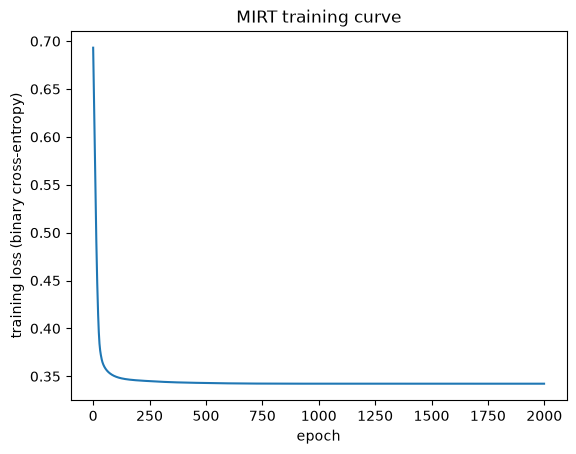

In [2]:
plt.plot(loss_history)
plt.xlabel("epoch")
plt.ylabel("training loss (binary cross-entropy)")
plt.title("MIRT training curve");

## Does it predict answers it hasn't seen?
The validation models were never used in training. For each one we reveal a random half of its answers,
estimate its θ from that half (with the questions' α and β frozen), and predict the hidden half.

Baseline: predict each question's accuracy on the training models, ignoring which model is answering.

In [3]:
def cross_entropy(predicted, actual):
    """Average binary cross-entropy. Clipping avoids log(0)."""
    predicted = np.clip(predicted, 1e-6, 1 - 1e-6)
    return -(actual * np.log(predicted) + (1 - actual) * np.log(1 - predicted)).mean()


rng = np.random.default_rng(0)
revealed = rng.random(Y_val.shape) < 0.5
hidden = ~revealed

# MIRT: estimate each validation model's ability from its revealed answers,
# then predict every question
theta_val = fit_theta(Y_val, revealed, alpha, beta, theta_prior=theta)
mirt_prob = predict_proba(theta_val, alpha, beta)

# Baseline: the same prediction for every model
baseline_prob = np.broadcast_to(Y_train.mean(axis=0), mirt_prob.shape)

# Score both on the hidden answers only
actual = Y_val[hidden]
pd.DataFrame(
    {
        "cross-entropy": [cross_entropy(baseline_prob[hidden], actual),
                          cross_entropy(mirt_prob[hidden], actual)],
        "accuracy": [((baseline_prob[hidden] > 0.5) == actual).mean(),
                     ((mirt_prob[hidden] > 0.5) == actual).mean()],
    },
    index=["question average (baseline)", "MIRT"],
).round(4)

,cross-entropy,accuracy
question average (baseline),0.4860,0.7640
MIRT,0.4077,0.8039


## What the learned parameters look like
The two axes can be rotated without changing any prediction, so θ₁ and θ₂ have no fixed meaning on their own.
Only the distances and angles between points carry meaning.

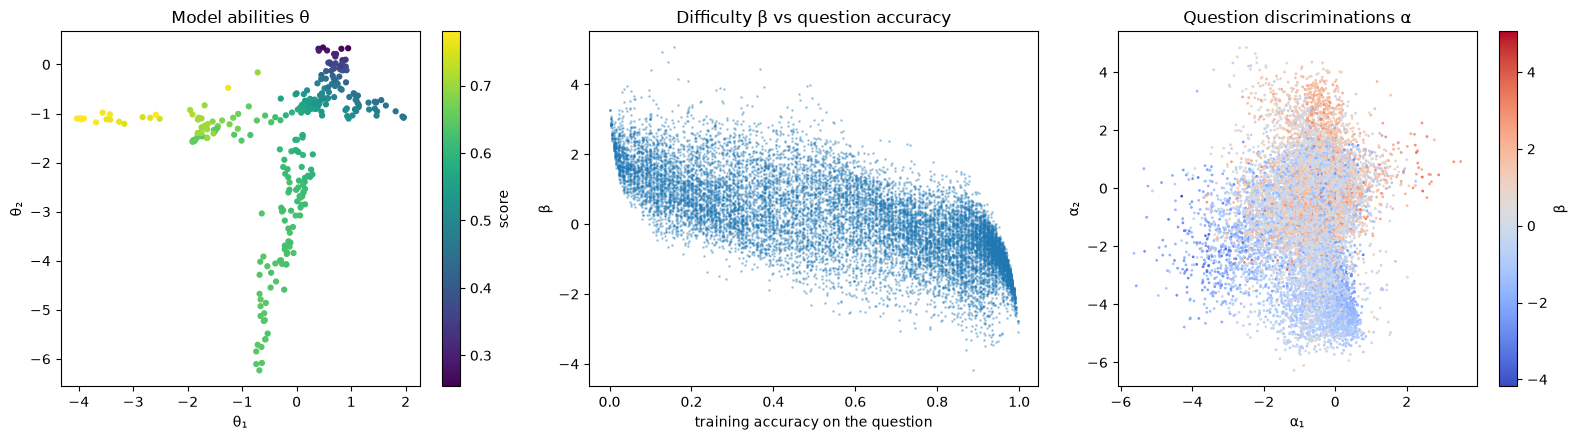

In [4]:
fig, (ax_theta, ax_beta, ax_alpha) = plt.subplots(1, 3, figsize=(16, 4.5))

# Each training model's 2-D ability, coloured by its real score
points = ax_theta.scatter(theta[:, 0], theta[:, 1], c=Y_train.mean(axis=1), s=12)
plt.colorbar(points, ax=ax_theta, label="score")
ax_theta.set(title="Model abilities θ", xlabel="θ₁", ylabel="θ₂")

# Difficulty should fall as more training models get the question right
ax_beta.scatter(Y_train.mean(axis=0), beta, s=1, alpha=0.3)
ax_beta.set(
    title="Difficulty β vs question accuracy",
    xlabel="training accuracy on the question",
    ylabel="β",
)

# Each question's discrimination direction, coloured by difficulty
points = ax_alpha.scatter(alpha[:, 0], alpha[:, 1], c=beta, cmap="coolwarm", s=1)
plt.colorbar(points, ax=ax_alpha, label="β")
ax_alpha.set(title="Question discriminations α", xlabel="α₁", ylabel="α₂")

plt.tight_layout()

## Which subjects does the second dimension pull apart?
For each subject, take the average α of its questions and measure its angle from the average α of *all* questions.
An angle doesn't change when the axes are rotated, so it can be compared across fits.
The subjects at the two extremes are the ones the second dimension separates most.

In [5]:
subject_alpha = (
    pd.DataFrame(alpha, columns=["alpha_1", "alpha_2"])
    .assign(subject=items.subject.values)
    .groupby("subject")
    .mean()
)

# Signed angle (in degrees) between each subject's mean alpha and the overall mean alpha
overall = alpha.mean(axis=0)
cross = overall[0] * subject_alpha.alpha_2 - overall[1] * subject_alpha.alpha_1
dot = subject_alpha.values @ overall
subject_alpha["angle"] = np.degrees(np.arctan2(cross, dot))

# The 5 subjects at each extreme
by_angle = subject_alpha.sort_values("angle").round(2)
pd.concat([by_angle.head(5), by_angle.tail(5)])

,alpha_1,alpha_2,angle
subject,,,
college_mathematics,-0.21,0.22,-101.519997
abstract_algebra,-0.25,0.20,-91.540001
global_facts,-0.30,0.23,-90.680000
high_school_mathematics,-0.20,0.15,-89.919998
high_school_physics,-0.34,0.24,-89.400002
us_foreign_policy,-0.78,-2.22,16.680000
miscellaneous,-0.68,-2.14,18.500000
high_school_european_history,-0.55,-1.78,18.910000
marketing,-0.65,-2.25,19.940001
